In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error


In [8]:
x_train = pd.read_csv('../data/processed/x_train_scaled.csv')
y_train = pd.read_csv('../data/processed/y_train.csv')
x_val = pd.read_csv('../data/processed/x_val_scaled.csv')
y_val = pd.read_csv('../data/processed/y_val.csv')
x_test = pd.read_csv('../data/processed/x_test_scaled.csv')
y_test = pd.read_csv('../data/processed/y_test.csv')

In [9]:
forest_model = RandomForestRegressor(n_estimators=100, random_state=42)
forest_model.fit(x_train, y_train.values.ravel())
y_pred = forest_model.predict(x_test)

In [10]:
print("Mean Squared Error:", mean_squared_error(y_test, y_pred))
print("R-squared:", r2_score(y_test, y_pred))
print("Mean Absolute Error:", mean_absolute_error(y_test, y_pred))

Mean Squared Error: 6052.5603190516185
R-squared: -1.1501791211986792
Mean Absolute Error: 65.84106521075137


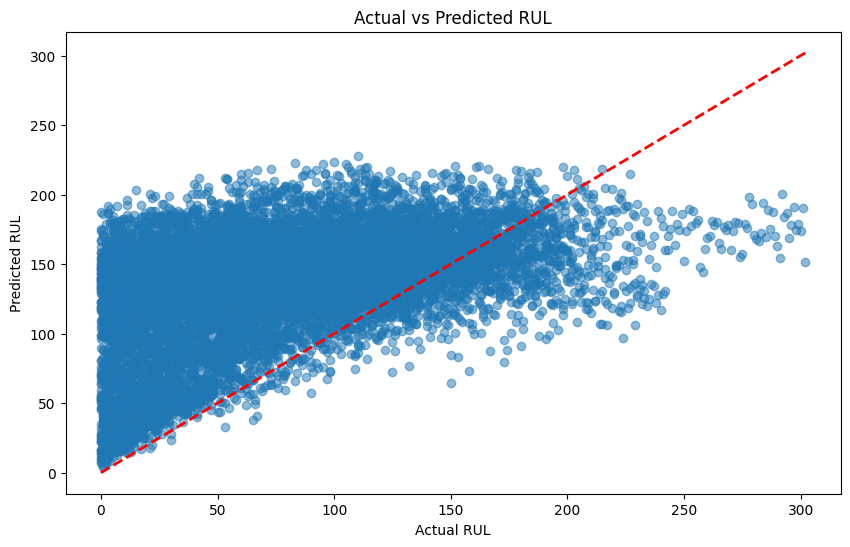

In [11]:
# plotting the predicted vs actual values
plt.figure(figsize=(10, 6))
plt.scatter(y_test, y_pred, alpha=0.5)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.xlabel('Actual RUL')
plt.ylabel('Predicted RUL')
plt.title('Actual vs Predicted RUL')    
plt.show()

In [22]:
print(y_test.shape)
print(y_pred.shape)

(13096, 1)
(13096,)


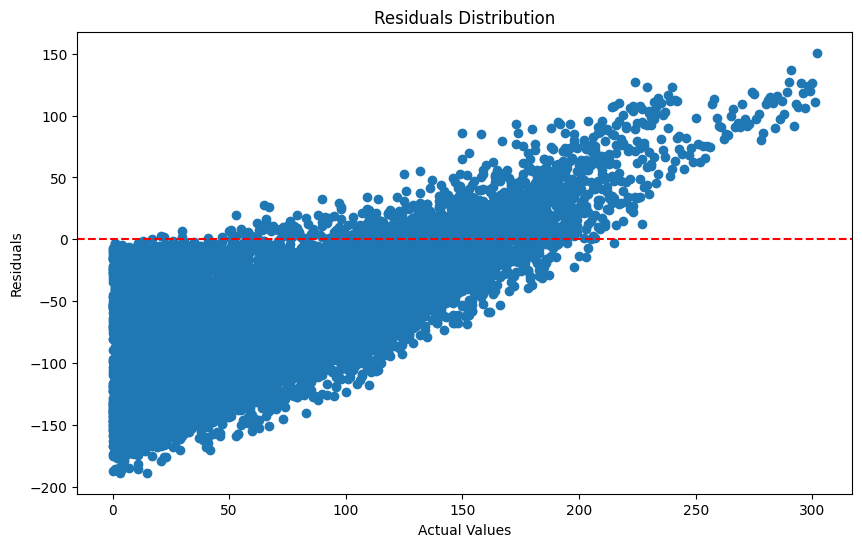

In [23]:
#plotting the residuals

y_pred = pd.DataFrame(y_pred, columns=['RUL'])
residuals = y_test - y_pred

plt.figure(figsize=(10, 6))
plt.scatter(x=y_test, y=residuals)
plt.axhline(y=0, color='r', linestyle='--')
plt.title('Residuals Distribution')
plt.xlabel('Actual Values')
plt.ylabel('Residuals')
plt.show()
